In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

np.random.seed(42)

# Generate sample data for hypothesis testing
data = np.random.normal(loc=10.5, scale=2, size=50)

print("Sample size:", len(data))
print("Sample mean:", round(np.mean(data), 4))
print("Sample standard deviation:", round(np.std(data, ddof=1), 4))

Sample size: 50
Sample mean: 10.0491
Sample standard deviation: 1.8673


In [2]:
# Define the null hypothesis and significance level
hypothesized_mean = 10
alpha = 0.05

# Perform a one-sample t-test
t_statistic, p_value = stats.ttest_1samp(data, popmean=hypothesized_mean)

print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value, 4))

if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

T-statistic: 0.1857
P-value: 0.8534
Fail to reject the null hypothesis.


In [3]:
# Calculate the 95% confidence interval for the population mean
sample_mean = np.mean(data)
standard_error = stats.sem(data)
confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(data) - 1,
    loc=sample_mean,
    scale=standard_error
)

print("95% Confidence Interval:")
print(
    f"Lower bound: {confidence_interval[0]:.4f}",
    f"| Upper bound: {confidence_interval[1]:.4f}"
)

95% Confidence Interval:
Lower bound: 9.5184 | Upper bound: 10.5797


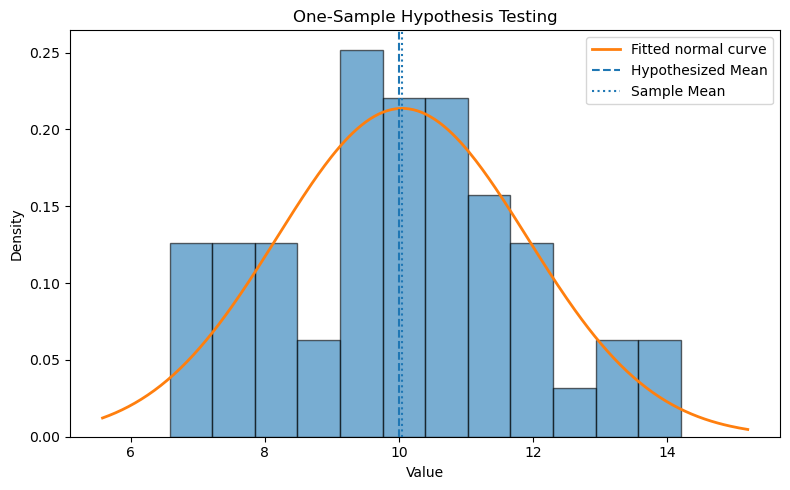

In [4]:
# Visualize the sample distribution and hypothesized mean
plt.figure(figsize=(8, 5))
plt.hist(data, bins=12, density=True, alpha=0.6, edgecolor="black")

x_values = np.linspace(data.min() - 1, data.max() + 1, 300)
plt.plot(
    x_values,
    stats.norm.pdf(x_values, loc=np.mean(data), scale=np.std(data, ddof=1)),
    linewidth=2,
    label="Fitted normal curve"
)

plt.axvline(
    hypothesized_mean,
    linestyle="--",
    label="Hypothesized Mean"
)
plt.axvline(
    sample_mean,
    linestyle=":",
    label="Sample Mean"
)

plt.xlabel("Value")
plt.ylabel("Density")
plt.title("One-Sample Hypothesis Testing")
plt.legend()
plt.tight_layout()

# Save the hypothesis testing plot
plt.savefig(
    "../reports/figures/hypothesis_testing.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
# Generate a second independent sample
group_a = np.random.normal(loc=10, scale=2, size=50)
group_b = np.random.normal(loc=11, scale=2.2, size=50)

# Perform Welch's t-test without assuming equal variances
t_statistic_two, p_value_two = stats.ttest_ind(
    group_a,
    group_b,
    equal_var=False
)

print("Welch's t-statistic:", round(t_statistic_two, 4))
print("P-value:", round(p_value_two, 4))

if p_value_two < alpha:
    print("Reject the null hypothesis: the group means differ.")
else:
    print("Fail to reject the null hypothesis: insufficient evidence of a difference.")

Welch's t-statistic: -2.1884
P-value: 0.0312
Reject the null hypothesis: the group means differ.


In [6]:
# Compile the hypothesis testing results
results = pd.DataFrame({
    "Test": [
        "One-Sample t-Test",
        "Welch's Two-Sample t-Test"
    ],
    "T-Statistic": [
        t_statistic,
        t_statistic_two
    ],
    "P-Value": [
        p_value,
        p_value_two
    ],
    "Significance Level": [alpha, alpha],
    "Decision": [
        "Reject H0" if p_value < alpha else "Fail to reject H0",
        "Reject H0" if p_value_two < alpha else "Fail to reject H0"
    ]
})

results.to_csv(
    "../reports/hypothesis_testing_results.csv",
    index=False
)

print("Hypothesis testing results saved successfully.")

results

Hypothesis testing results saved successfully.


,Test,T-Statistic,P-Value,Significance Level,Decision
0,One-Sample t-Test,0.185746,0.853410,0.05,Fail to reject H0
1,Welch's Two-Sample t-Test,-2.188441,0.031152,0.05,Reject H0
